# US Diabetes Dataset — EDA, Visualization and Preprocessing

This notebook follows a simple, step-by-step Pandas style.

**Dataset note:** `diabetic_data.csv` is a hospital encounter dataset for patients with diabetes. Its `readmitted` column describes hospital readmission (`NO`, `>30`, `<30`); it does not directly diagnose diabetes.

**Before running:** Put `diabetic_data.csv` in the same folder as this notebook.


## 1. Import libraries

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


## 2. Load the dataset

In [7]:
df = pd.read_csv("data/diabetic_data.csv")

df.head()


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 3. Understand the data

In [8]:
print("Rows and columns:", df.shape)


Rows and columns: (101766, 50)


In [9]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [10]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766.0,NaN,NaN,NaN,54330400.694947,38696359.346534,135.0,23413221.0,45505143.0,87545949.75,189502619.0
race,101766,6,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,101766,10,?,98569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


## 4. Check duplicate rows

In [11]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


## 5. Convert '?' to missing values

In [12]:
data = df.copy()
data.replace("?", np.nan, inplace=True)

data.isnull().sum().sort_values(ascending=False).head(20)


weight                      98569
max_glu_serum               96420
A1Cresult                   84748
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
patient_nbr                     0
time_in_hospital                0
admission_source_id             0
num_lab_procedures              0
encounter_id                    0
admission_type_id               0
discharge_disposition_id        0
gender                          0
age                             0
number_inpatient                0
number_emergency                0
dtype: int64

## 6. Missing-value summary

In [13]:
missing_count = data.isnull().sum()
missing_percent = (missing_count / len(data)) * 100

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})

missing_summary = missing_summary.sort_values("missing_percent", ascending=False)
missing_summary.head(20)


,missing_count,missing_percent
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636
patient_nbr,0,0.000000


## 7. Visualization: missing values

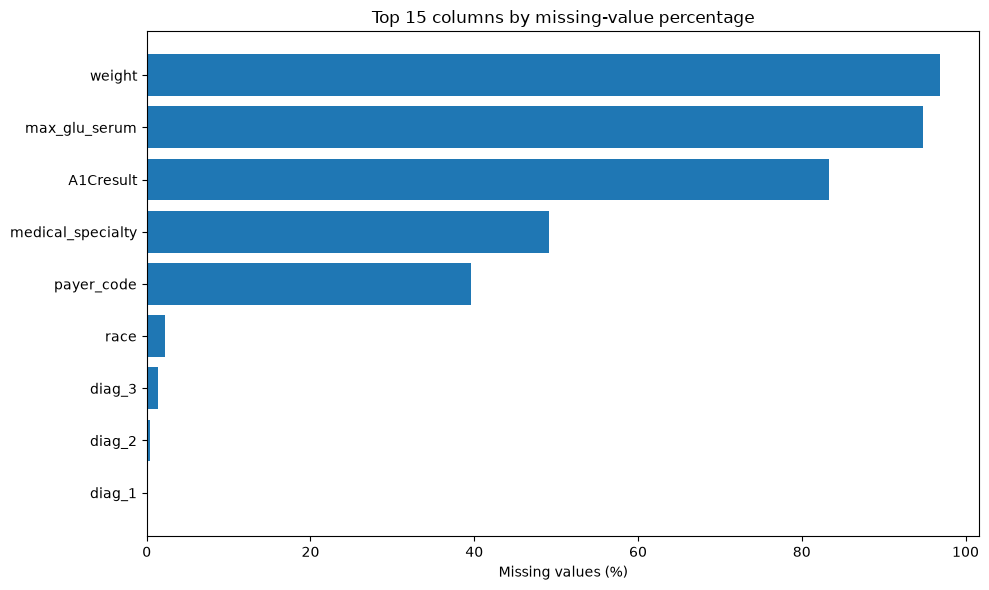

In [14]:
missing_plot = missing_summary[missing_summary["missing_count"] > 0].head(15)

plt.figure(figsize=(10, 6))
plt.barh(missing_plot.index[::-1], missing_plot["missing_percent"].iloc[::-1])
plt.xlabel("Missing values (%)")
plt.title("Top 15 columns by missing-value percentage")
plt.tight_layout()
plt.show()


## 8. Explore the target: readmission

In [15]:
data["readmitted"].value_counts(dropna=False)


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

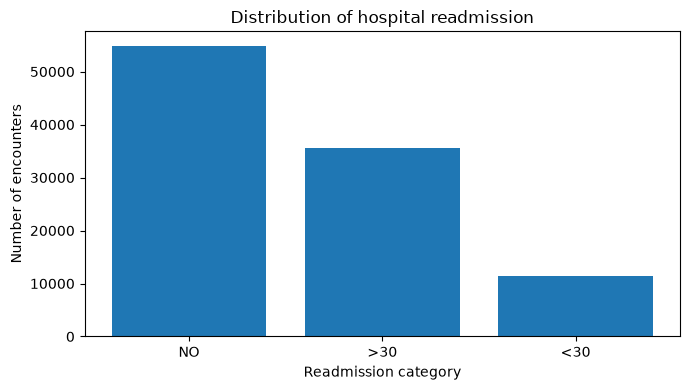

In [16]:
readmission_counts = data["readmitted"].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(readmission_counts.index.astype(str), readmission_counts.values)
plt.xlabel("Readmission category")
plt.ylabel("Number of encounters")
plt.title("Distribution of hospital readmission")
plt.tight_layout()
plt.show()


In [17]:
readmission_percent = data["readmitted"].value_counts(normalize=True) * 100
readmission_percent


readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

## 9. Explore age

In [18]:
data["age"].value_counts().sort_index()


age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

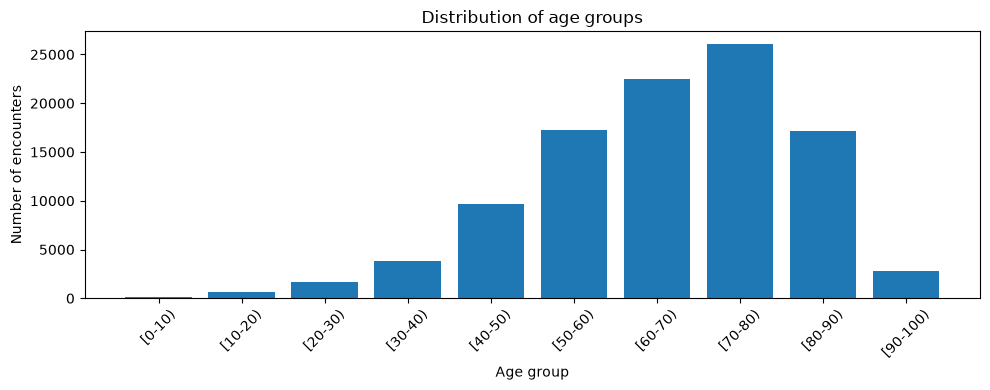

In [19]:
age_counts = data["age"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xlabel("Age group")
plt.ylabel("Number of encounters")
plt.title("Distribution of age groups")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 10. Explore gender

In [20]:
data["gender"].value_counts(dropna=False)


gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

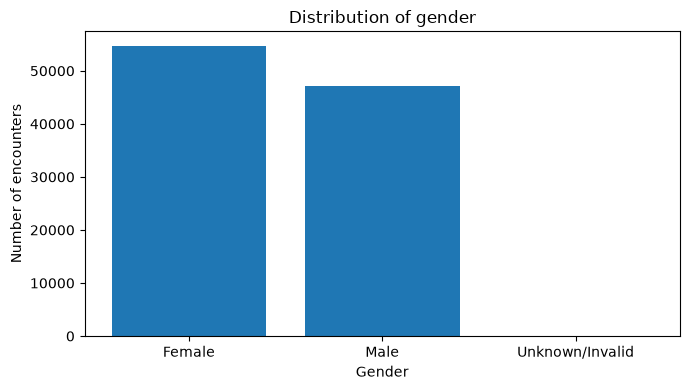

In [21]:
gender_counts = data["gender"].value_counts(dropna=False)

plt.figure(figsize=(7, 4))
plt.bar(gender_counts.index.astype(str), gender_counts.values)
plt.xlabel("Gender")
plt.ylabel("Number of encounters")
plt.title("Distribution of gender")
plt.tight_layout()
plt.show()


## 11. Readmission by age group

In [22]:
readmission_by_age = pd.crosstab(data["age"], data["readmitted"], normalize="index") * 100
readmission_by_age


readmitted,<30,>30,NO
age,,,
[0-10),1.863354,16.149068,81.987578
[10-20),5.788712,32.416787,61.794501
[20-30),14.242607,30.778515,54.978877
[30-40),11.231788,31.443709,57.324503
[40-50),10.604027,33.846154,55.549819
[50-60),9.666203,34.289522,56.044274
[60-70),11.128408,35.124316,53.747276
[70-80),11.773055,36.347246,51.879699
[80-90),12.083503,36.186544,51.729953


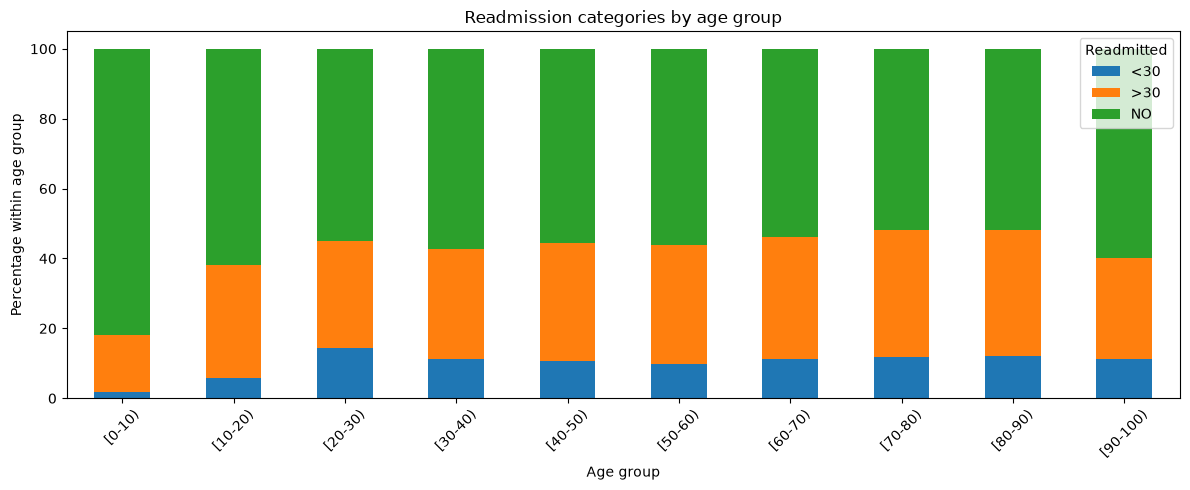

In [23]:
readmission_by_age.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.xlabel("Age group")
plt.ylabel("Percentage within age group")
plt.title("Readmission categories by age group")
plt.legend(title="Readmitted")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 12. Explore admission type

In [24]:
data["admission_type_id"].value_counts(dropna=False).sort_index()


admission_type_id
1    53990
2    18480
3    18869
4       10
5     4785
6     5291
7       21
8      320
Name: count, dtype: int64

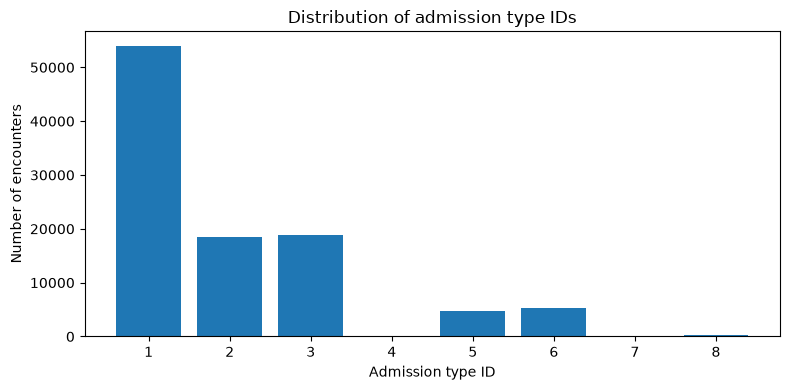

In [25]:
admission_counts = data["admission_type_id"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(admission_counts.index.astype(str), admission_counts.values)
plt.xlabel("Admission type ID")
plt.ylabel("Number of encounters")
plt.title("Distribution of admission type IDs")
plt.tight_layout()
plt.show()


## 13. Explore glucose and A1C result categories

In [26]:
print("Max glucose serum results:")
print(data["max_glu_serum"].value_counts(dropna=False))

print("\\nA1C results:")
print(data["A1Cresult"].value_counts(dropna=False))


Max glucose serum results:
max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64
\nA1C results:
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


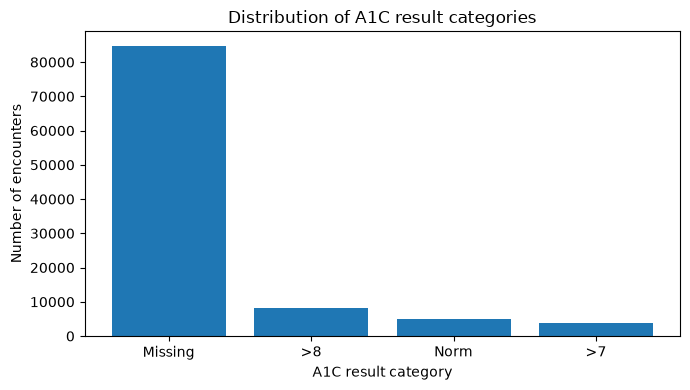

In [27]:
a1c_counts = data["A1Cresult"].fillna("Missing").value_counts()

plt.figure(figsize=(7, 4))
plt.bar(a1c_counts.index.astype(str), a1c_counts.values)
plt.xlabel("A1C result category")
plt.ylabel("Number of encounters")
plt.title("Distribution of A1C result categories")
plt.tight_layout()
plt.show()


## 14. Number of medications

In [28]:
data["num_medications"].describe()


count    101766.000000
mean         16.021844
std           8.127566
min           1.000000
25%          10.000000
50%          15.000000
75%          20.000000
max          81.000000
Name: num_medications, dtype: float64

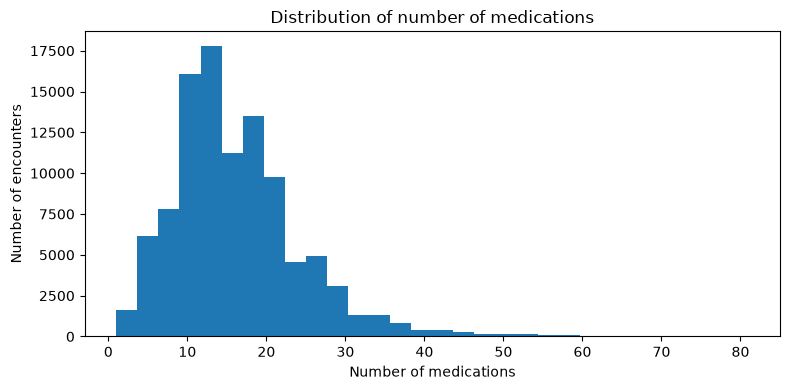

In [29]:
plt.figure(figsize=(8, 4))
plt.hist(data["num_medications"].dropna(), bins=30)
plt.xlabel("Number of medications")
plt.ylabel("Number of encounters")
plt.title("Distribution of number of medications")
plt.tight_layout()
plt.show()


## 15. Readmission by A1C result

In [30]:
readmission_by_a1c = pd.crosstab(
    data["A1Cresult"].fillna("Missing"),
    data["readmitted"],
    normalize="index"
) * 100

readmission_by_a1c


readmitted,<30,>30,NO
A1Cresult,,,
>7,10.047219,34.102833,55.849948
>8,9.870983,35.309153,54.819864
Missing,11.423278,35.098173,53.478548
Norm,9.659319,32.044088,58.296593


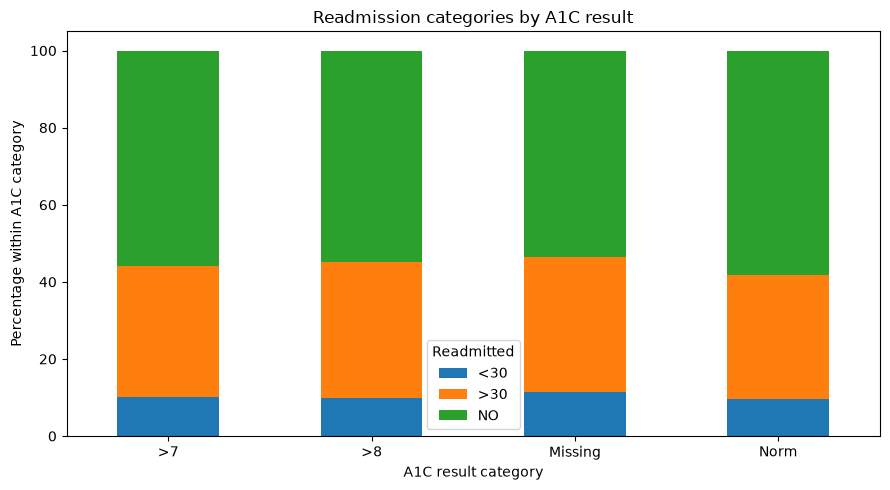

In [31]:
readmission_by_a1c.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.xlabel("A1C result category")
plt.ylabel("Percentage within A1C category")
plt.title("Readmission categories by A1C result")
plt.legend(title="Readmitted")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 16. Preprocessing notes

### What we have done
- Loaded and inspected the dataset.
- Checked duplicates.
- Replaced the `?` markers with missing values in `data`.
- Summarized missing values.
- Explored readmission, age, gender, admission type, A1C results and medication counts with charts.

### Important decisions still needed
- Do not automatically delete every row with a missing value; some columns have a large amount of missing data.
- Decide which columns to retain based on the prediction goal.
- Check identifiers such as `encounter_id` and `patient_nbr` before modeling.
- Encode categorical columns only after deciding the model and features.
- Split into training and test sets before fitting imputers, scalers or encoders to avoid data leakage.
- This dataset supports a hospital-readmission analysis, not a direct diabetes diagnosis.


## 17. Save the stage-one cleaned dataset

In [32]:
data.to_csv("diabetic_data_preprocessed_stage1.csv", index=False)
print("Saved: diabetic_data_preprocessed_stage1.csv")


Saved: diabetic_data_preprocessed_stage1.csv
